# Superstore Sales & Profitability Analysis

## Business objective
Analyze sales and profitability to identify
underperforming products, categories, and regions.

## Research questions
1. How do sales and profit change over time?
2. Which categories and sub-categories are most profitable?
3. Which regions contribute most to profit?
4. How are discounts associated with profitability?
5. Which products generate high sales but low or negative profit?

In [26]:
from pathlib import Path

print("Текущая рабочая папка:")
print(Path.cwd())

print("\nCSV-файлы, которые Python может найти:")

for folder in [Path("data"), Path("../data")]:
    if folder.exists():
        for file in folder.glob("*.csv"):
            print(file.resolve())

Текущая рабочая папка:
c:\Users\Admin\OneDrive\Рабочий стол\superstore-sales-analysis\notebooks

CSV-файлы, которые Python может найти:
C:\Users\Admin\OneDrive\Рабочий стол\superstore-sales-analysis\data\Sample - Superstore.csv


In [27]:
import pandas as pd
from pathlib import Path

# Ищем CSV в папке проекта
folders = [Path("data"), Path("../data")]

csv_files = [
    file
    for folder in folders if folder.exists()
    for file in folder.glob("*.csv")
]

if not csv_files:
    print("CSV-файл не найден. Проверь папку data.")
else:
    data_path = csv_files[0]
    df = pd.read_csv(data_path, encoding="cp1252")

    print("Файл загружен:", data_path.name)
    print("Количество строк и столбцов:", df.shape)

    display(df.head())

Файл загружен: Sample - Superstore.csv
Количество строк и столбцов: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [28]:
# Общая информация о таблице
print("Размер таблицы:", df.shape)

print("\nТипы данных и количество непустых значений:")
df.info()

print("\nСтатистики числовых столбцов:")
display(df.describe().T)

Размер таблицы: (9994, 21)

Типы данных и количество непустых значений:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-

,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.500000,2885.163629,1.000,2499.25000,4997.5000,7495.750,9994.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.00000,56430.5000,90008.000,99301.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


In [29]:
# Количество пропусков в каждом столбце
missing = df.isna().sum()

print("Столбцы с пропущенными значениями:")
display(missing[missing > 0].sort_values(ascending=False))

# Количество полностью повторяющихся строк
print("Полных дубликатов:", df.duplicated().sum())

# Проверка повторов по идентификатору строки
print("Повторяющихся Row ID:", df["Row ID"].duplicated().sum())

Столбцы с пропущенными значениями:


Series([], dtype: int64)

Полных дубликатов: 0
Повторяющихся Row ID: 0


In [30]:
print("Тип Order Date:", df["Order Date"].dtype)
print("Тип Ship Date:", df["Ship Date"].dtype)

Тип Order Date: object
Тип Ship Date: object


In [31]:
# 1. Проверяем пропуски
print("Количество пропусков:", df.isna().sum().sum())

# 2. Проверяем полные дубликаты
print("Полных дубликатов:", df.duplicated().sum())

# 3. Проверяем уникальность Row ID
print("Всего значений Row ID:", df["Row ID"].count())
print("Уникальных Row ID:", df["Row ID"].nunique())

# 4. Проверяем даты
print("\nТип Order Date:", df["Order Date"].dtype)
print("Тип Ship Date:", df["Ship Date"].dtype)

# 5. Проверяем диапазоны дат
print("\nПримеры дат заказов:")
print(df["Order Date"].head().to_list())

Количество пропусков: 0
Полных дубликатов: 0
Всего значений Row ID: 9994
Уникальных Row ID: 9994

Тип Order Date: object
Тип Ship Date: object

Примеры дат заказов:
['11/8/2016', '11/8/2016', '6/12/2016', '10/11/2015', '10/11/2015']


In [32]:
# Преобразуем даты в формат datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y",
    errors="raise"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%m/%d/%Y",
    errors="raise"
)

print("Новый тип Order Date:", df["Order Date"].dtype)
print("Новый тип Ship Date:", df["Ship Date"].dtype)

print(
    "Период заказов:",
    df["Order Date"].min().date(),
    "—",
    df["Order Date"].max().date()
)

Новый тип Order Date: datetime64[ns]
Новый тип Ship Date: datetime64[ns]
Период заказов: 2014-01-03 — 2017-12-30


In [33]:
# Основные бизнес-показатели

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products_sold = df["Quantity"].sum()
profit_margin = total_profit / total_sales * 100

print(f"Общая выручка: ${total_sales:,.2f}")
print(f"Общая прибыль: ${total_profit:,.2f}")
print(f"Количество заказов: {total_orders:,}")
print(f"Количество клиентов: {total_customers:,}")
print(f"Продано единиц товара: {total_products_sold:,}")
print(f"Рентабельность продаж: {profit_margin:.2f}%")

Общая выручка: $2,297,200.86
Общая прибыль: $286,397.02
Количество заказов: 5,009
Количество клиентов: 793
Продано единиц товара: 37,873
Рентабельность продаж: 12.47%


In [34]:
# Сводная таблица по категориям

category_analysis = (
    df.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
)

category_analysis["Profit Margin (%)"] = (
    category_analysis["Profit"] /
    category_analysis["Sales"] * 100
)

category_analysis = category_analysis.sort_values(
    "Profit", ascending=False
)

display(category_analysis.round(2))

,Category,Sales,Profit,Quantity,Orders,Profit Margin (%)
2,Technology,836154.03,145454.95,6939,1544,17.40
1,Office Supplies,719047.03,122490.80,22906,3742,17.04
0,Furniture,741999.80,18451.27,8028,1764,2.49


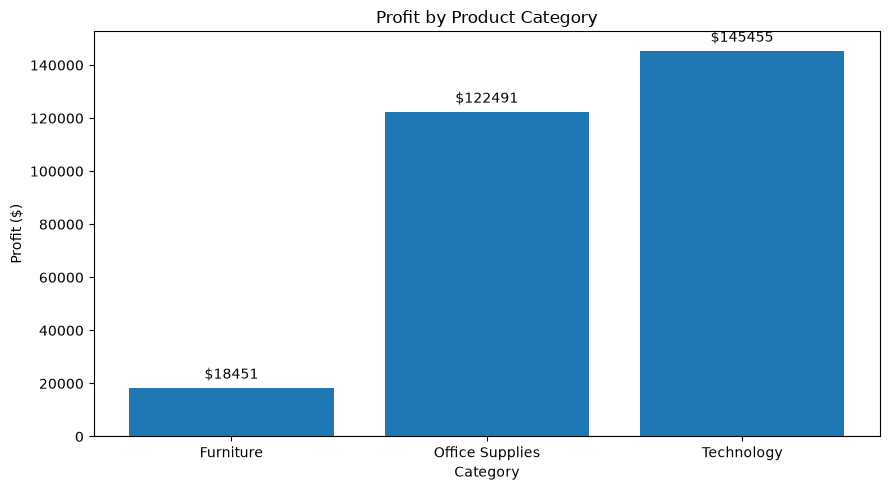

In [35]:
import matplotlib.pyplot as plt

plot_data = category_analysis.sort_values("Profit")

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data["Category"],
    plot_data["Profit"]
)

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit ($)")
plt.axhline(0, linewidth=0.8)

# Подписи над столбцами
plt.bar_label(bars, fmt="$%.0f", padding=4)

plt.tight_layout()
plt.show()

In [36]:
subcategory_analysis = (
    df.groupby(["Category", "Sub-Category"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)

subcategory_analysis["Profit Margin (%)"] = (
    subcategory_analysis["Profit"]
    / subcategory_analysis["Sales"] * 100
)

# Сначала посмотрим на самые убыточные подкатегории
display(
    subcategory_analysis
    .sort_values("Profit")
    [["Category", "Sub-Category", "Sales", "Profit", "Profit Margin (%)"]]
    .head(5)
    .round(2)
)

,Category,Sub-Category,Sales,Profit,Profit Margin (%)
3,Furniture,Tables,206965.53,-17725.48,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,-2.55
8,Office Supplies,Fasteners,3024.28,949.52,31.40
15,Technology,Machines,189238.63,3384.76,1.79


In [37]:
# Анализ результатов при разных уровнях скидки

discount_analysis = (
    df.groupby("Discount")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Rows=("Row ID", "count")
    )
    .reset_index()
)

discount_analysis["Profit Margin (%)"] = (
    discount_analysis["Profit"]
    / discount_analysis["Sales"] * 100
)

display(
    discount_analysis
    .sort_values("Discount")
    .round(2)
)

,Discount,Sales,Profit,Quantity,Rows,Profit Margin (%)
0,0.00,1087908.47,320987.60,18267,4798,29.51
1,0.10,54369.35,9029.18,373,94,16.61
2,0.15,27558.52,1418.99,198,52,5.15
3,0.20,764594.37,90337.31,13660,3657,11.82
4,0.30,103226.66,-10369.28,849,227,-10.05
5,0.32,14493.46,-2391.14,105,27,-16.50
6,0.40,116417.78,-23057.05,786,206,-19.81
7,0.45,5484.97,-2493.11,45,11,-45.45
8,0.50,58918.54,-20506.43,241,66,-34.80
9,0.60,6644.70,-5944.66,501,138,-89.46


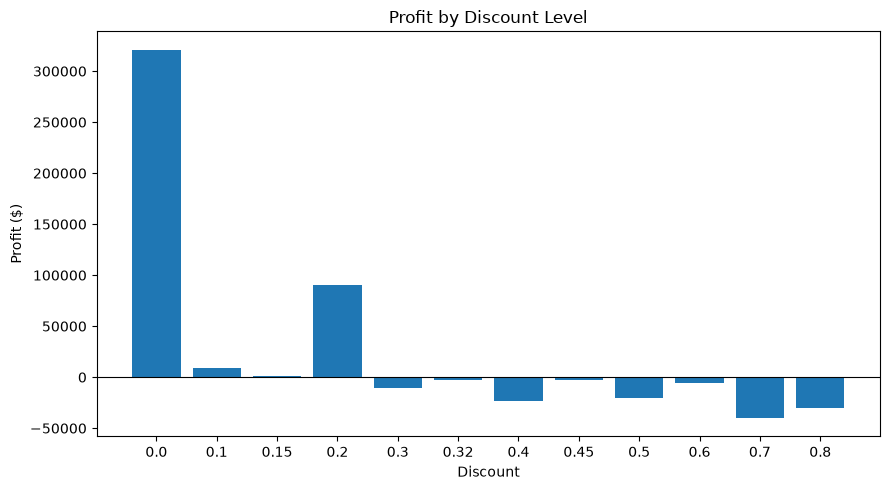

In [38]:
import matplotlib.pyplot as plt

plot_data = discount_analysis.sort_values("Discount")

plt.figure(figsize=(9, 5))
plt.bar(
    plot_data["Discount"].astype(str),
    plot_data["Profit"]
)

plt.title("Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [39]:
discount_by_category = (
    df.groupby(["Category", "Discount"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Rows=("Row ID", "count")
    )
    .reset_index()
)

discount_by_category["Profit Margin (%)"] = (
    discount_by_category["Profit"]
    / discount_by_category["Sales"] * 100
)

display(
    discount_by_category[
        discount_by_category["Discount"] >= 0.30
    ]
    .sort_values(["Category", "Discount"])
    .round(2)
)

,Category,Discount,Sales,Profit,Rows,Profit Margin (%)
4,Furniture,0.30,99470.35,-10695.32,222,-10.75
5,Furniture,0.32,14493.46,-2391.14,27,-16.50
6,Furniture,0.40,45614.41,-16187.40,75,-35.49
7,Furniture,0.45,5484.97,-2493.11,11,-45.45
8,Furniture,0.50,20983.47,-12871.20,54,-61.34
9,Furniture,0.60,6644.70,-5944.66,138,-89.46
10,Furniture,0.70,2459.38,-3894.94,15,-158.37
14,Office Supplies,0.70,22559.39,-16601.10,380,-73.59
15,Office Supplies,0.80,16963.76,-30539.04,300,-180.03
19,Technology,0.30,3756.30,326.04,5,8.68


In [40]:
# Анализ скидок для отдельных подкатегорий

subcategory_discount = (
    df.groupby(["Sub-Category", "Discount"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Rows=("Row ID", "count")
    )
    .reset_index()
)

subcategory_discount["Profit Margin (%)"] = (
    subcategory_discount["Profit"]
    / subcategory_discount["Sales"] * 100
)

# Показываем комбинации подкатегорий и скидок
# с отрицательной суммарной прибылью
loss_combinations = (
    subcategory_discount[
        subcategory_discount["Profit"] < 0
    ]
    .sort_values("Profit")
)

display(
    loss_combinations[
        [
            "Sub-Category",
            "Discount",
            "Sales",
            "Profit",
            "Rows",
            "Profit Margin (%)"
        ]
    ]
    .head(10)
    .round(2)
)

,Sub-Category,Discount,Sales,Profit,Rows,Profit Margin (%)
11,Binders,0.8,13581.22,-21909.40,233,-161.32
41,Machines,0.7,15601.51,-19579.32,23,-125.50
10,Binders,0.7,22559.39,-16601.10,380,-73.59
54,Tables,0.4,45614.41,-16187.40,75,-35.49
5,Appliances,0.8,3382.53,-8629.64,67,-255.12
56,Tables,0.5,13675.01,-8615.39,36,-63.00
40,Machines,0.5,37935.07,-7635.23,12,-20.13
22,Chairs,0.3,70005.50,-6737.12,158,-9.62
46,Phones,0.4,34337.35,-6385.79,109,-18.60
32,Furnishings,0.6,6644.70,-5944.66,138,-89.46


In [41]:
# Анализ прибыли по конкретным товарам

product_analysis = (
    df.groupby(["Product ID", "Product Name", "Category", "Sub-Category"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Rows=("Row ID", "count")
    )
    .reset_index()
)

product_analysis["Profit Margin (%)"] = (
    product_analysis["Profit"]
    / product_analysis["Sales"] * 100
)

# Десять товаров с наибольшим суммарным убытком
worst_products = product_analysis.sort_values("Profit").head(10)

display(
    worst_products[
        [
            "Product ID",
            "Product Name",
            "Category",
            "Sub-Category",
            "Sales",
            "Profit",
            "Quantity",
            "Profit Margin (%)"
        ]
    ].round(2)
)

,Product ID,Product Name,Category,Sub-Category,Sales,Profit,Quantity,Profit Margin (%)
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.96,-8879.97,9,-80.00
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.90,-4589.97,18,-27.27
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.98,-3839.99,4,-48.00
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,9917.64,-2876.12,27,-29.00
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,9544.72,-1934.40,33,-20.27
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.07,-1878.17,27,-10.45
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.48,-1811.08,6,-8.00
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,Office Supplies,Supplies,16656.20,-1299.18,22,-7.80
346,FUR-TA-10001950,Balt Solid Wood Round Tables,Furniture,Tables,6518.75,-1201.06,19,-18.42
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,1706.25,-1148.44,15,-67.31


In [42]:
print(df[["Product ID", "Product Name"]].head(10).to_string(index=False))

     Product ID                                                     Product Name
FUR-BO-10001798                                Bush Somerset Collection Bookcase
FUR-CH-10000454      Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back
OFF-LA-10000240        Self-Adhesive Address Labels for Typewriters by Universal
FUR-TA-10000577                    Bretford CR4500 Series Slim Rectangular Table
OFF-ST-10000760                                   Eldon Fold 'N Roll Cart System
FUR-FU-10001487 Eldon Expressions Wood and Plastic Desk Accessories, Cherry Wood
OFF-AR-10002833                                                       Newell 322
TEC-PH-10002275                                   Mitel 5320 IP Phone VoIP phone
OFF-BI-10003910             DXL Angle-View Binders with Locking Rings by Samsill
OFF-AP-10002892                                 Belkin F5C206VTEL 6 Outlet Surge


In [43]:
worst_product_ids = worst_products["Product ID"]

worst_product_details = df[
    df["Product ID"].isin(worst_product_ids)
].groupby(
    ["Product ID", "Product Name", "Category", "Sub-Category"]
).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean"),
    Max_Discount=("Discount", "max"),
    Quantity=("Quantity", "sum"),
    Rows=("Row ID", "count")
).reset_index()

worst_product_details["Profit Margin (%)"] = (
    worst_product_details["Profit"]
    / worst_product_details["Sales"] * 100
)

display(
    worst_product_details
    .sort_values("Profit")
    .round(2)
)

,Product ID,Product Name,Category,Sub-Category,Sales,Profit,Avg_Discount,Max_Discount,Quantity,Rows,Profit Margin (%)
6,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.96,-8879.97,0.53,0.7,9,3,-80.00
7,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.90,-4589.97,0.40,0.7,18,4,-27.27
9,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.98,-3839.99,0.50,0.5,4,1,-48.00
0,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,9917.64,-2876.12,0.28,0.4,27,5,-29.00
1,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,9544.72,-1934.40,0.35,0.5,33,7,-20.27
4,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.07,-1878.17,0.45,0.8,27,6,-10.45
8,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.48,-1811.08,0.50,0.5,6,1,-8.00
5,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,Office Supplies,Supplies,16656.20,-1299.18,0.10,0.2,22,6,-7.80
2,FUR-TA-10001950,Balt Solid Wood Round Tables,Furniture,Tables,6518.75,-1201.06,0.20,0.4,19,4,-18.42
3,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,1706.25,-1148.44,0.48,0.5,15,3,-67.31


In [44]:
# Повторно рассчитываем показатели по товарам
product_analysis = (
    df.groupby(
        ["Product ID", "Product Name", "Category", "Sub-Category"],
        as_index=False
    )
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Rows=("Row ID", "count"),
        Avg_Discount=("Discount", "mean"),
        Max_Discount=("Discount", "max")
    )
)

product_analysis["Profit Margin (%)"] = (
    product_analysis["Profit"]
    / product_analysis["Sales"] * 100
)

worst_products = (
    product_analysis
    .sort_values("Profit")
    .head(10)
    .reset_index(drop=True)
)

display(
    worst_products[
        [
            "Product ID",
            "Product Name",
            "Category",
            "Sub-Category",
            "Sales",
            "Profit",
            "Avg_Discount",
            "Max_Discount",
            "Quantity",
            "Rows",
            "Profit Margin (%)"
        ]
    ].round(2)
)

,Product ID,Product Name,Category,Sub-Category,Sales,Profit,Avg_Discount,Max_Discount,Quantity,Rows,Profit Margin (%)
0,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.96,-8879.97,0.53,0.7,9,3,-80.00
1,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.90,-4589.97,0.40,0.7,18,4,-27.27
2,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.98,-3839.99,0.50,0.5,4,1,-48.00
3,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,9917.64,-2876.12,0.28,0.4,27,5,-29.00
4,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,9544.72,-1934.40,0.35,0.5,33,7,-20.27
5,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.07,-1878.17,0.45,0.8,27,6,-10.45
6,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.48,-1811.08,0.50,0.5,6,1,-8.00
7,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,Office Supplies,Supplies,16656.20,-1299.18,0.10,0.2,22,6,-7.80
8,FUR-TA-10001950,Balt Solid Wood Round Tables,Furniture,Tables,6518.75,-1201.06,0.20,0.4,19,4,-18.42
9,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,1706.25,-1148.44,0.48,0.5,15,3,-67.31


In [45]:
print(product_analysis.columns.tolist())
print(product_analysis[
    ["Product ID", "Product Name"]
].head(3).to_string(index=False))

['Product ID', 'Product Name', 'Category', 'Sub-Category', 'Sales', 'Profit', 'Quantity', 'Rows', 'Avg_Discount', 'Max_Discount', 'Profit Margin (%)']
     Product ID                                                   Product Name
FUR-BO-10000112               Bush Birmingham Collection Bookcase, Dark Cherry
FUR-BO-10000330 Sauder Camden County Barrister Bookcase, Planked Cherry Finish
FUR-BO-10000362                             Sauder Inglewood Library Bookcases


In [46]:
from pathlib import Path

# Создаём папку для подготовленных данных
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Основные данные
df.to_csv(
    output_dir / "superstore_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. Прибыль по категориям
category_analysis.to_csv(
    output_dir / "category_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Прибыль по подкатегориям и скидкам
subcategory_discount.to_csv(
    output_dir / "subcategory_discount.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. Анализ товаров
product_analysis.to_csv(
    output_dir / "product_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Файлы сохранены в:", output_dir.resolve())

for file in output_dir.glob("*.csv"):
    print(file.name, "-", file.stat().st_size, "байт")

Файлы сохранены в: C:\Users\Admin\OneDrive\Рабочий стол\superstore-sales-analysis\data\processed
category_analysis.csv - 257 байт
product_analysis.csv - 257166 байт
subcategory_discount.csv - 3325 байт
superstore_clean.csv - 2317084 байт
